# Día 7 — Taller: proyecto final «Pronosticando la economía»

**Módulo 5: Econometría y Forecasting con IA — CEC EPN / Banco Central del Ecuador**  
**Fecha:** 12-11-2026 · **Unidad 5. Taller de Forecasting** · Contenidos 5.3, 5.4 y 5.5 · **Proyecto final** (40 puntos, individual)

Este es el **notebook base** del proyecto. Ya trae todas las herramientas de la semana, organizadas en el orden del trabajo. Tu tarea es **tomar las decisiones**, ejecutar, interpretar y escribir.

## Qué se entrega

1. **Este notebook**, ejecutado de principio a fin, con tus decisiones y conclusiones escritas en las celdas marcadas **Tu decisión** o **Tu interpretación**.
2. **Un informe ejecutivo de una página en PDF**, dirigido a un público no técnico (parte 9).

## Cómo se evalúa (rúbrica, 40 puntos)

| Criterio | Puntos | Dónde se evidencia |
|---|---:|---|
| Planteamiento | 5 | parte 1 |
| Preparación y validación | 8 | partes 2 y 3 |
| Aplicación de métodos | 10 | partes 4 a 6 |
| Comparación e interpretación | 8 | partes 5 y 7 |
| Informe ejecutivo | 9 | parte 9 y PDF |

## Cómo usar este notebook

- Las celdas de **código** ya funcionan. Ejecútalas en orden. Puedes modificarlas, pero cada cambio debe estar justificado.
- Las celdas **Tu decisión** y **Tu interpretación** son tuyas: reemplaza el texto de ejemplo con tus palabras y tus cifras.
- El notebook se entrega **ejecutado con la serie que elegiste**. Los textos de ejemplo usan la inflación; si eliges otra serie, cámbialos.

# 0. Herramientas

Todas las funciones de esta celda las construimos durante la semana. Se agrupan aquí para que el resto del notebook sea corto y legible.

| Función | Qué hace | Día |
|---|---|---|
| `prueba_adf` | prueba de estacionariedad ADF | 2 |
| `pronosticos_simples` | ingenuo, ingenuo estacional, promedio móvil, media histórica a un paso | 1 |
| `backtesting` | origen móvil a 1–3 meses, reestimando en cada origen | 2 y 6 |
| `ajustar_arima` | estima un ARIMA o SARIMA | 3 |
| `traducir_a_anual` | de inflación mensual a inflación anual (solo para el IPC) | 6 |

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.metrics import mean_absolute_error, mean_squared_error

import warnings
warnings.filterwarnings('ignore')


def prueba_adf(serie):
    estadistico, p_valor, rezagos, *_ = adfuller(serie.dropna(), autolag='AIC', result_object=False)
    return {'estadistico': round(estadistico, 2), 'p_valor': round(p_valor, 4), 'rezagos': rezagos,
            'conclusion': 'estacionaria' if p_valor < 0.05 else 'NO estacionaria'}


def ajustar_arima(serie, order, seasonal_order=(0, 0, 0, 0)):
    """Estima un ARIMA/SARIMA. Incluye constante solo si no hay diferenciación."""
    tendencia = 'c' if order[1] == 0 and seasonal_order[1] == 0 else 'n'
    return ARIMA(serie, order=order, seasonal_order=seasonal_order, trend=tendencia).fit()


def pronosticar_metodo(historia, metodo, h, k=12, order=None, seasonal_order=(0, 0, 0, 0)):
    """Pronóstico para los h meses siguientes al final de `historia`."""
    if metodo == 'ingenuo':
        return np.repeat(historia.iloc[-1], h)
    if metodo == 'ingenuo_estacional':
        return np.array([historia.iloc[-12 * int(np.ceil(i / 12)) + (i - 1) % 12] for i in range(1, h + 1)])
    if metodo == 'promedio_movil':
        return np.repeat(historia.iloc[-k:].mean(), h)
    if metodo == 'arima':
        return ajustar_arima(historia, order, seasonal_order).get_forecast(steps=h).predicted_mean.values
    raise ValueError(metodo)


def backtesting(serie, metodos, desde, h=3, paso=1):
    """Origen móvil: para cada origen, reestima con la historia y pronostica h meses. Devuelve una tabla larga."""
    origenes = pd.date_range(desde, serie.index.max() - pd.DateOffset(months=h), freq=f'{paso}MS')
    filas = []
    for origen in origenes:
        historia = serie.loc[:origen]
        for nombre, parametros in metodos.items():
            pron = pronosticar_metodo(historia, h=h, **parametros)
            for i in range(1, h + 1):
                mes = origen + pd.DateOffset(months=i)
                filas.append({'origen': origen, 'mes': mes, 'h': i, 'metodo': nombre,
                              'real': serie.loc[mes], 'pronostico': pron[i - 1]})
    tabla = pd.DataFrame(filas)
    tabla['error'] = tabla['real'] - tabla['pronostico']
    return tabla


def resumen_errores(tabla):
    g = tabla.groupby(['metodo', 'h'])['error']
    return pd.DataFrame({'MAE': g.apply(lambda e: e.abs().mean()),
                         'RMSE': g.apply(lambda e: np.sqrt((e ** 2).mean())),
                         'Sesgo': g.mean()})


def traducir_a_anual(indice, variaciones_mensuales):
    """Encadena variaciones mensuales sobre el último índice y calcula la inflación anual de cada mes futuro."""
    meses = pd.date_range(indice.index[-1] + pd.DateOffset(months=1), periods=len(variaciones_mensuales), freq='MS')
    futuro = pd.Series(indice.iloc[-1] * np.cumprod(1 + np.asarray(variaciones_mensuales) / 100), index=meses)
    return (futuro.values / indice.loc[meses - pd.DateOffset(months=12)].values - 1) * 100

print('Herramientas listas.')

Herramientas listas.


In [2]:
# Ubicamos la carpeta de datos sin depender de si Jupyter se abrió
# desde la carpeta raíz o desde la carpeta notebooks/.
DATA_DIR = Path('datos') if Path('datos').exists() else Path('../datos')

print('Usando datos desde:', DATA_DIR.resolve())

Usando datos desde: /tmp/m5repo/datos


# 1. Planteamiento (5 puntos)

## 1.1 Elige tu serie

| Opción | Columna | Fuente | Desde | Unidad |
|---|---|---|---|---|
| 1. Inflación mensual | `ipc_var_mensual` | INEC | 1969 (usar desde 2005) | % mensual |
| 2. Tasa activa referencial | `tasa_activa_ref_pct` | BCE | 2015 | % anual |
| 3. Balanza comercial | `balanza_comercial_musd` | BCE | 1990 | millones USD FOB |

Cambia `SERIE` y `DESDE` en la celda siguiente.

In [3]:
# ======================= TUS DECISIONES DE PARTIDA =======================
SERIE = 'ipc_var_mensual'      # 'ipc_var_mensual', 'tasa_activa_ref_pct' o 'balanza_comercial_musd'
DESDE_SUGERIDO = {'ipc_var_mensual': '2005', 'tasa_activa_ref_pct': '2015', 'balanza_comercial_musd': '2005'}
DESDE = DESDE_SUGERIDO[SERIE]   # inicio del entrenamiento; puedes cambiarlo justificándolo
HORIZONTE = 3                   # meses a pronosticar (fijo en el proyecto)
# =========================================================================

UNIDADES = {'ipc_var_mensual': '% mensual', 'tasa_activa_ref_pct': '% anual', 'balanza_comercial_musd': 'millones USD'}
UNIDAD = UNIDADES[SERIE]

series = pd.read_csv(DATA_DIR / 'series_economicas.csv', parse_dates=['fecha'], index_col='fecha').asfreq('MS')
y = series[SERIE].loc[DESDE:].dropna()

print(f'{SERIE}: {len(y)} meses, de {y.index.min():%b %Y} a {y.index.max():%b %Y} · unidad: {UNIDAD}')

ipc_var_mensual: 260 meses, de Jan 2005 a Aug 2026 · unidad: % mensual


## 1.2 Tu decisión: la ficha del problema

*Reemplaza el ejemplo con tu propia ficha.*

| Campo | Tu respuesta |
|---|---|
| **Pregunta** | *Ejemplo: ¿cuál será la inflación mensual del Ecuador en septiembre, octubre y noviembre de 2026?* |
| **Para quién** | *Ejemplo: el área de estudios económicos, que debe estimar la inflación anual de cierre de año.* |
| **Unidad y frecuencia** | *% de variación mensual del IPC; mensual.* |
| **Horizonte** | 3 meses |
| **Periodo de entrenamiento** | *Desde 2005: la economía dolarizada consolidada (Día 5, parte 8).* |
| **Métrica principal** | MAE (en la unidad de la serie); RMSE como complemento |
| **Línea base** | *Promedio móvil de 12 meses (el más difícil de superar en los Días 1–6).* |

# 2. Preparación y revisión (parte de los 8 puntos)

## 2.1 Fechas, frecuencia y faltantes

In [4]:
calendario = pd.date_range(y.index.min(), y.index.max(), freq='MS')

print('Frecuencia:', y.index.freqstr)
print('Meses esperados:', len(calendario), '· meses con dato:', y.notna().sum())
print('Fechas repetidas:', y.index.duplicated().sum())
y.describe().round(3)

Frecuencia: MS
Meses esperados: 260 · meses con dato: 260
Fechas repetidas: 0


count    260.000
mean       0.212
std        0.368
min       -0.986
25%       -0.005
50%        0.173
75%        0.399
max        1.518
Name: ipc_var_mensual, dtype: float64

## 2.2 Gráfico de la serie

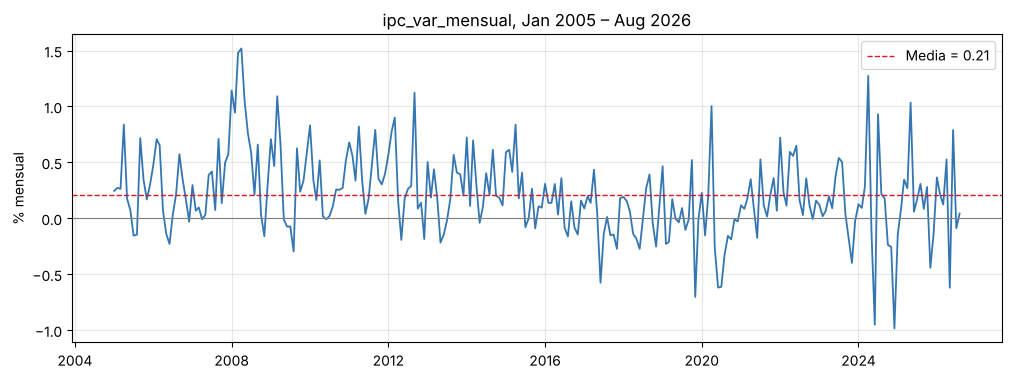

In [5]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(y, color='#3476B1', linewidth=1.3)
ax.axhline(y.mean(), color='#DA181E', linestyle='--', linewidth=1, label=f'Media = {y.mean():.2f}')
ax.axhline(0, color='gray', linewidth=0.8)
ax.set_ylabel(UNIDAD)
ax.set_title(f'{SERIE}, {y.index.min():%b %Y} – {y.index.max():%b %Y}')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## 2.3 Componentes y atípicos (Día 1)

Usamos STL robusta para separar tendencia, estacionalidad y residuo, y marcamos como atípicos los meses con residuo a más de 2.5 desviaciones estándar.

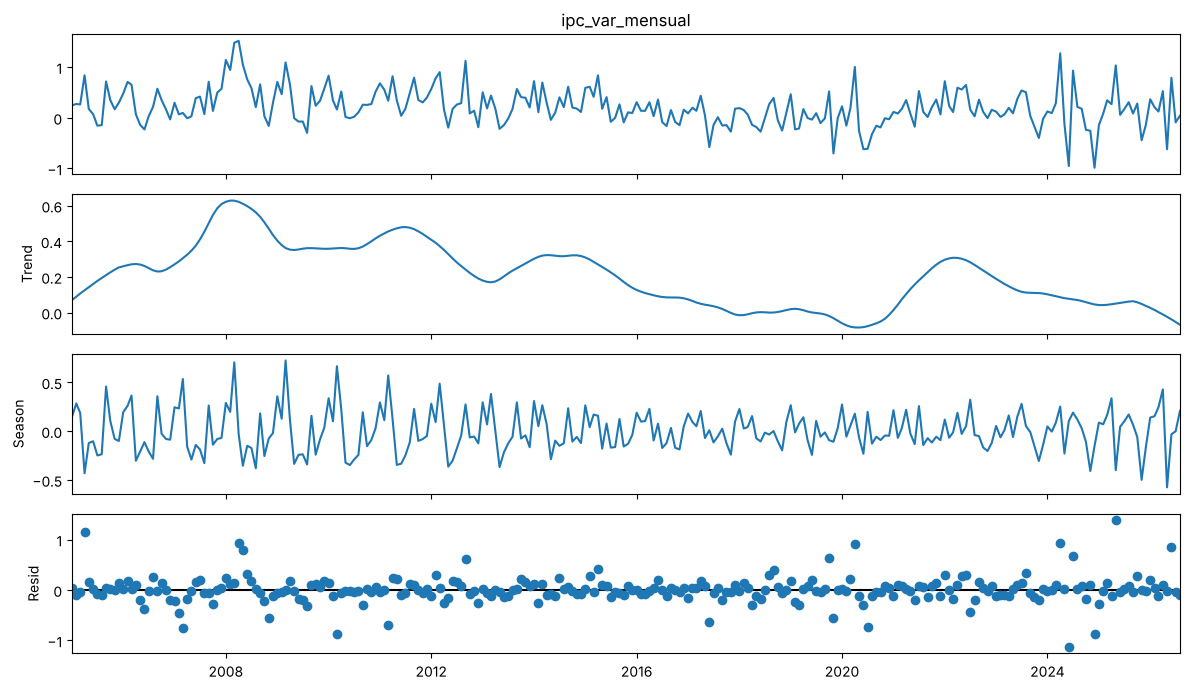

Atípicos por residuo: 13


,valor
fecha,
Apr 2005,0.84
Mar 2007,0.10
Apr 2008,1.52
May 2008,1.05
Mar 2010,0.16
Mar 2011,0.34
Apr 2020,1.00
Jul 2020,-0.61
Apr 2024,1.27


In [6]:
stl = STL(y, period=12, robust=True).fit()
fig = stl.plot()
fig.set_size_inches(12, 7)
plt.tight_layout()
plt.show()

z = (stl.resid - stl.resid.mean()) / stl.resid.std()
atipicos = y[z.abs() > 2.5]
print('Atípicos por residuo:', len(atipicos))
atipicos.round(2).rename(index=lambda f: f.strftime('%b %Y')).to_frame('valor')

### Tu interpretación

*¿Qué tendencia y estacionalidad observas? ¿Qué pasó en los meses atípicos (busca el hecho económico)? ¿Los mantienes, los reemplazas o los marcas? Justifica.*

*Ejemplo (inflación): la tendencia cambia por etapas (alta en 2008, baja en 2017–2020, repunte en 2022); la estacionalidad muestra picos en abril y septiembre. Los atípicos se concentran en 2008 (alimentos), 2020 (pandemia) y 2024 (alza del IVA en abril y su efecto posterior). Se mantienen, porque son hechos reales que pueden repetirse; se anotan para interpretar los errores de la parte 7.*

## 2.4 Estacionariedad y autocorrelación (Día 2)

In [7]:
pd.DataFrame({
    'Serie': prueba_adf(y),
    'Primera diferencia': prueba_adf(y.diff()),
}).T

,estadistico,p_valor,rezagos,conclusion
Serie,-2.77,0.0624,13,NO estacionaria
Primera diferencia,-9.41,0.0,10,estacionaria


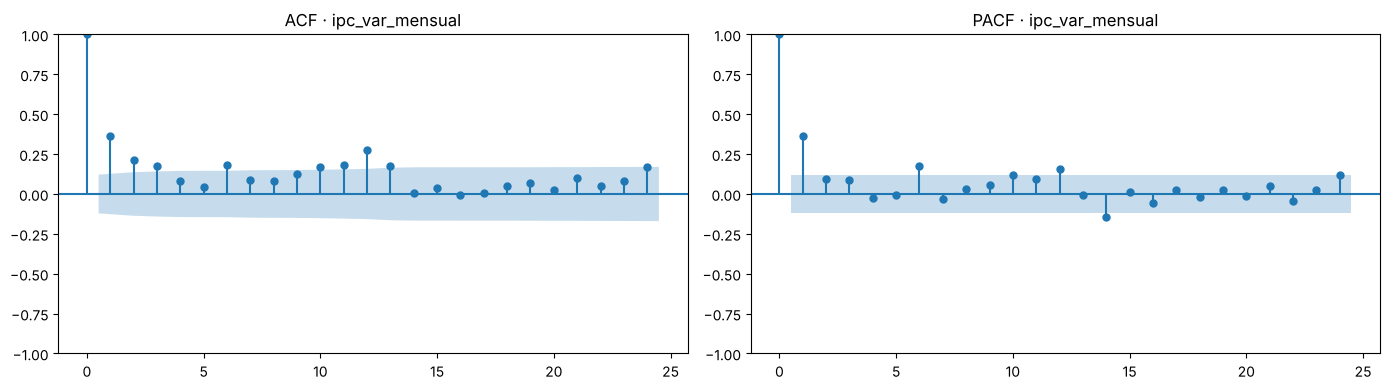

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(y, lags=24, ax=axes[0], title=f'ACF · {SERIE}')
plot_pacf(y, lags=24, ax=axes[1], title=f'PACF · {SERIE}', method='ywm')
plt.tight_layout()
plt.show()

### Tu decisión: candidatos de modelo

*Con la ADF, el gráfico y la ACF/PACF, decide $d$ y propón $p$, $q$ y la parte estacional. Escríbelos en la celda de la parte 4.*

*Ejemplo (inflación): la ADF con AIC da p ≈ 0.06, al límite; con BIC (Día 2) sí rechaza, y la serie no tiene tendencia sostenida ni varianza creciente → $d = 0$. La PACF se corta en 1 → $p = 1$; hay un bastón en el rezago 12 → $P = 1$. Candidatos: ARIMA(1,0,0) y SARIMA(1,0,0)(1,0,0)₁₂.*

# 3. División cronológica y esquema de validación (parte de los 8 puntos)

| Bloque | Periodo | Uso |
|---|---|---|
| Historia inicial | desde `DESDE` hasta el primer origen | primera estimación |
| **Origen móvil** | desde `INICIO_BACKTEST` hasta 3 meses antes del último dato | medir el error a 1, 2 y 3 meses, reestimando en cada origen |
| Los últimos meses del backtesting | los más recientes | también sirven como "Test": se revisan aparte |

**Nunca** se usa una partición aleatoria.

In [9]:
# Primer origen del backtesting: deja al menos 5 años de historia inicial.
INICIO_BACKTEST = (y.index.min() + pd.DateOffset(years=5)).strftime('%Y-%m-01')
INICIO_RECIENTE = '2025-01-01'   # para revisar aparte el periodo más reciente

print('Primer origen del backtesting:', INICIO_BACKTEST)
print('Orígenes:', len(pd.date_range(INICIO_BACKTEST, y.index.max() - pd.DateOffset(months=HORIZONTE), freq='MS')))

Primer origen del backtesting: 2010-01-01
Orígenes: 197


# 4. Métodos (10 puntos)

Debes comparar **al menos un método simple** y **al menos un modelo visto en el módulo**. Edita el diccionario `METODOS`:

- métodos simples: `'ingenuo'`, `'ingenuo_estacional'`, `'promedio_movil'` (con `k`);
- modelos: `'arima'` con `order` y, si quieres, `seasonal_order`.

El backtesting reestima los ARIMA en **cada origen**; con muchos orígenes puede tardar uno o dos minutos.

**Importante:** los candidatos que vienen escritos son los de la **inflación**. Si elegiste otra serie, cámbialos según tu parte 2.4. Por ejemplo, la tasa activa y la balanza no son estacionarias con la ADF: prueba modelos con $d = 1$, como `(0, 1, 1)` o `(1, 1, 0)`, y en la balanza agrega la parte estacional.

In [10]:
# ======================= TUS CANDIDATOS =======================
METODOS = {
    'Ingenuo':           {'metodo': 'ingenuo'},
    'Promedio móvil 12': {'metodo': 'promedio_movil', 'k': 12},
    'ARIMA(1,0,0)':      {'metodo': 'arima', 'order': (1, 0, 0)},
    'SARIMA(1,0,0)(1,0,0)12': {'metodo': 'arima', 'order': (1, 0, 0), 'seasonal_order': (1, 0, 0, 12)},
}
# ==============================================================

bt = backtesting(y, METODOS, desde=INICIO_BACKTEST, h=HORIZONTE)
print('Pronósticos evaluados:', len(bt))

Pronósticos evaluados: 2364


# 5. Comparación (parte de los 8 puntos)

## 5.1 Error por método y horizonte

In [11]:
errores = resumen_errores(bt)
errores['MAE'].unstack('h').round(3).sort_values(1)

h,1,2,3
metodo,,,
Promedio móvil 12,0.249,0.251,0.252
"SARIMA(1,0,0)(1,0,0)12",0.250,0.248,0.243
"ARIMA(1,0,0)",0.259,0.271,0.273
Ingenuo,0.307,0.345,0.347


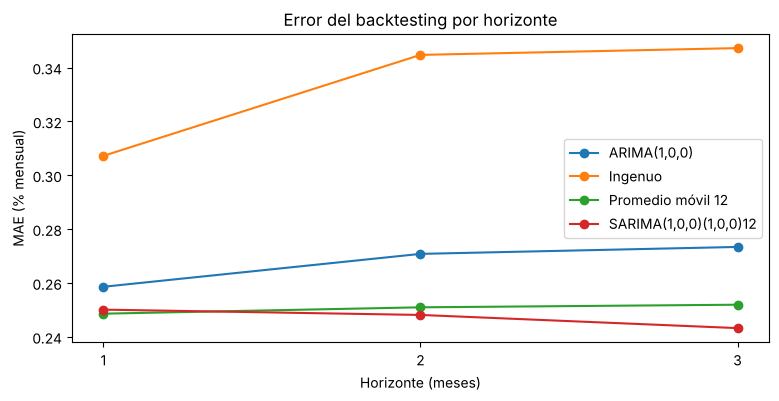

In [12]:
fig, ax = plt.subplots(figsize=(9, 4))
for metodo, fila in errores['MAE'].unstack('h').iterrows():
    ax.plot(fila.index, fila.values, marker='o', label=metodo)
ax.set_xticks(range(1, HORIZONTE + 1))
ax.set_xlabel('Horizonte (meses)')
ax.set_ylabel(f'MAE ({UNIDAD})')
ax.set_title('Error del backtesting por horizonte')
ax.legend()
plt.show()

## 5.2 El periodo más reciente, por separado

In [13]:
reciente = bt[bt['mes'] >= INICIO_RECIENTE]
pd.DataFrame({
    'MAE_todo_el_backtesting': bt.groupby('metodo')['error'].apply(lambda e: e.abs().mean()),
    'MAE_desde_2025': reciente.groupby('metodo')['error'].apply(lambda e: e.abs().mean()),
    'Sesgo_todo': bt.groupby('metodo')['error'].mean(),
}).sort_values('MAE_todo_el_backtesting').round(3)

,MAE_todo_el_backtesting,MAE_desde_2025,Sesgo_todo
metodo,,,
"SARIMA(1,0,0)(1,0,0)12",0.247,0.325,-0.055
Promedio móvil 12,0.250,0.296,-0.008
"ARIMA(1,0,0)",0.268,0.286,-0.093
Ingenuo,0.333,0.456,-0.002


### Tu interpretación

El **sesgo** es el promedio de (real − pronóstico): positivo significa que el modelo se queda corto en promedio; negativo, que se pasa.

*¿Qué método tiene menor MAE? ¿La diferencia es grande frente al error típico? ¿Cambia la conclusión en el periodo más reciente? ¿Hay sesgo? Explica las cifras en la unidad de la serie.*

*Ejemplo (inflación): el promedio móvil de 12 y el SARIMA empatan, con MAE ≈ 0.25 puntos a 1 mes; la diferencia es de milésimas. El ingenuo es claramente peor (0.31). Desde 2025 el orden cambia: ARIMA(1,0,0) 0.29, promedio móvil 0.30, SARIMA 0.33; ningún método domina siempre. El ARIMA y el SARIMA tienen sesgo negativo (se pasan en ≈ 0.05–0.09 puntos); el promedio móvil casi no tiene sesgo. Elegimos el promedio móvil: igual de preciso, sin sesgo y más fácil de explicar.*

## 5.3 Tu decisión: el modelo elegido

In [14]:
# ======================= TU ELECCIÓN =======================
MODELO_ELEGIDO = errores['MAE'].unstack('h')[1].idxmin()   # por defecto: menor MAE a 1 mes; puedes escribir el nombre
# ===========================================================
print('Modelo elegido:', MODELO_ELEGIDO)

Modelo elegido: Promedio móvil 12


*Justifica la elección en dos o tres líneas: precisión, estabilidad entre horizontes, simplicidad y facilidad de explicación.*

# 6. Pronóstico de los próximos tres meses (parte de los 10 puntos)

Reestimamos el modelo elegido con **toda** la serie. Los escenarios usan los cuantiles 10 % y 90 % de los errores del backtesting del modelo elegido (Día 6).

- **bajo_p10**: pronóstico + cuantil 10 % del error. Solo 1 de cada 10 veces el valor real quedó por debajo.
- **alto_p90**: pronóstico + cuantil 90 % del error. Solo 1 de cada 10 veces quedó por encima.

Si el escenario bajo es "optimista" o "pesimista" depende de la serie: en la inflación y la tasa, bajo es favorable; en la balanza comercial, alto es favorable (más superávit).

In [15]:
parametros = METODOS[MODELO_ELEGIDO]
pron = pronosticar_metodo(y, h=HORIZONTE, **parametros)
meses = pd.date_range(y.index.max() + pd.DateOffset(months=1), periods=HORIZONTE, freq='MS')

q = bt[bt['metodo'] == MODELO_ELEGIDO].groupby('h')['error'].quantile([0.10, 0.90]).unstack()

escenarios = pd.DataFrame({
    'bajo_p10': pron + q[0.10].values,
    'base': pron,
    'alto_p90': pron + q[0.90].values,
}, index=meses)

# Si el modelo es ARIMA, agregamos su intervalo del 80 %.
if parametros['metodo'] == 'arima':
    intervalo = ajustar_arima(y, parametros['order'], parametros.get('seasonal_order', (0, 0, 0, 0))) \
        .get_forecast(steps=HORIZONTE).conf_int(alpha=0.20)
    escenarios['ARIMA_inf80'] = intervalo.iloc[:, 0].values
    escenarios['ARIMA_sup80'] = intervalo.iloc[:, 1].values

escenarios.round(3)

,bajo_p10,base,alto_p90
2026-09-01,-0.252,0.094,0.480
2026-10-01,-0.247,0.094,0.480
2026-11-01,-0.247,0.094,0.481


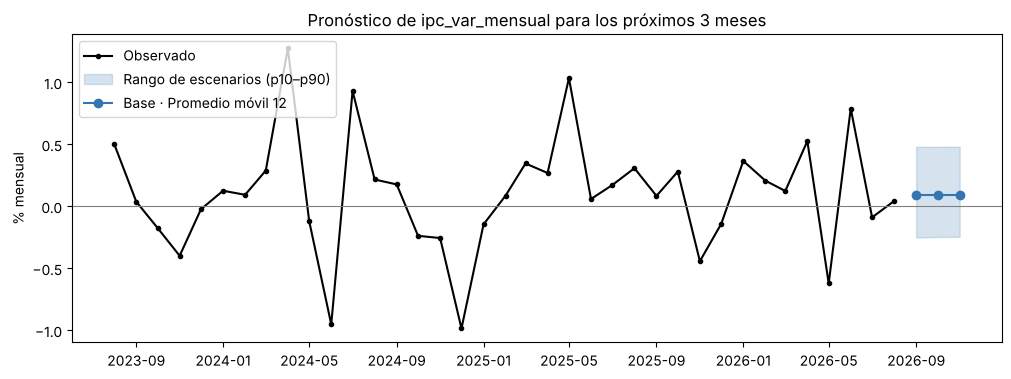

In [16]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(y.loc[y.index.max() - pd.DateOffset(months=36):], color='black', marker='o', markersize=3, label='Observado')
ax.fill_between(escenarios.index, escenarios['bajo_p10'], escenarios['alto_p90'],
                color='#3476B1', alpha=0.2, label='Rango de escenarios (p10–p90)')
ax.plot(escenarios['base'], color='#3476B1', marker='o', label=f'Base · {MODELO_ELEGIDO}')
ax.axhline(0, color='gray', linewidth=0.8)
ax.set_ylabel(UNIDAD)
ax.set_title(f'Pronóstico de {SERIE} para los próximos {HORIZONTE} meses')
ax.legend(loc='upper left')
plt.show()

## 6.1 Traducción para quien decide

Para la inflación, convertimos el pronóstico mensual en **inflación anual** (Día 6, parte 5). Para las otras series, la traducción es distinta: en la tasa activa, el costo de un crédito; en la balanza, el saldo acumulado del trimestre.

In [17]:
if SERIE == 'ipc_var_mensual':
    indice = series['ipc_indice'].dropna()
    traduccion = pd.DataFrame({c: traducir_a_anual(indice, escenarios[c]) for c in ['bajo_p10', 'base', 'alto_p90']},
                              index=meses)
    print('Inflación anual proyectada (%):')
    display(traduccion.round(2))
elif SERIE == 'balanza_comercial_musd':
    print('Saldo acumulado de los próximos 3 meses (millones USD):')
    display(escenarios[['bajo_p10', 'base', 'alto_p90']].sum().round(0).to_frame('acumulado'))
else:
    print('Tasa activa pronosticada al final del horizonte (%):')
    display(escenarios.iloc[[-1]][['bajo_p10', 'base', 'alto_p90']].round(2))

Inflación anual proyectada (%):


,bajo_p10,base,alto_p90
2026-09-01,0.78,1.13,1.52
2026-10-01,0.25,0.94,1.72
2026-11-01,0.45,1.49,2.67


# 7. Visualización e interpretación de errores (5.4)

## 7.1 Pronósticos del backtesting frente a lo real

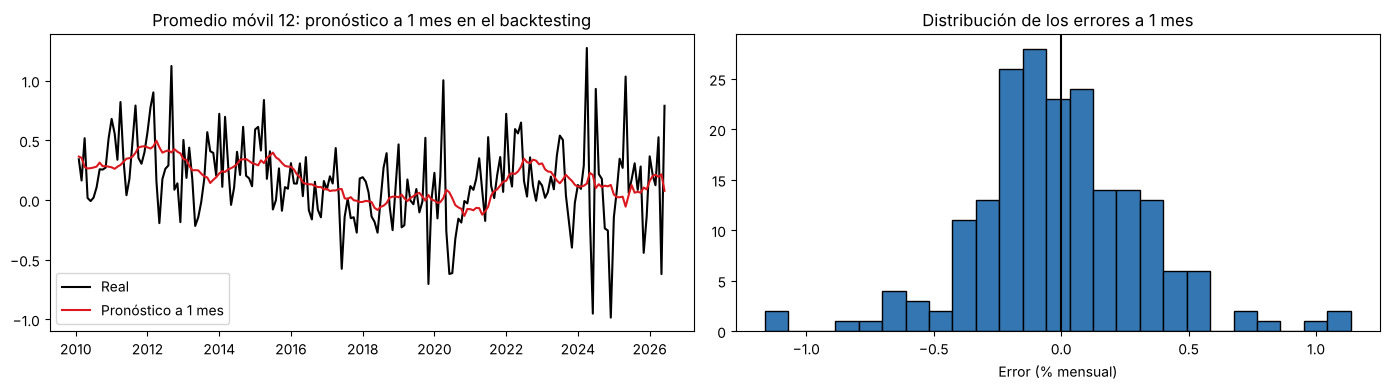

Errores más grandes a 1 mes:


mes
Jun 2024    1.162
Apr 2024    1.136
Dec 2024    1.112
May 2025    1.090
Apr 2020    0.987
Name: error, dtype: float64

In [18]:
uno = bt[(bt['metodo'] == MODELO_ELEGIDO) & (bt['h'] == 1)].set_index('mes')

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(uno['real'], color='black', label='Real')
axes[0].plot(uno['pronostico'], color='#DA181E', label='Pronóstico a 1 mes')
axes[0].set_title(f'{MODELO_ELEGIDO}: pronóstico a 1 mes en el backtesting')
axes[0].legend()

axes[1].hist(uno['error'], bins=25, color='#3476B1', edgecolor='black')
axes[1].axvline(0, color='black')
axes[1].set_title('Distribución de los errores a 1 mes')
axes[1].set_xlabel(f'Error ({UNIDAD})')
plt.tight_layout()
plt.show()

print('Errores más grandes a 1 mes:')
uno['error'].abs().nlargest(5).round(3).rename(index=lambda f: f.strftime('%b %Y'))

### Tu interpretación

*¿En qué meses se equivocó más el modelo? ¿Coinciden con los atípicos de la parte 2? ¿Qué hecho económico los explica? ¿El modelo llega tarde a los cambios?*

## 7.2 Residuos del modelo (solo si elegiste un ARIMA)

In [19]:
if parametros['metodo'] == 'arima':
    final = ajustar_arima(y, parametros['order'], parametros.get('seasonal_order', (0, 0, 0, 0)))
    print(final.summary().tables[1])
    print('Ljung-Box (p-valor, 12 rezagos):', round(acorr_ljungbox(final.resid, lags=[12])['lb_pvalue'].iloc[0], 3))
else:
    print('El modelo elegido no es un ARIMA: no tiene residuos de un modelo estimado.')

El modelo elegido no es un ARIMA: no tiene residuos de un modelo estimado.


# 8. Guardar resultados

In [20]:
carpeta = Path('resultados_proyecto')
carpeta.mkdir(exist_ok=True)

escenarios.round(3).to_csv(carpeta / f'pronostico_{SERIE}.csv')
errores.round(4).to_csv(carpeta / f'errores_backtesting_{SERIE}.csv')
print('Guardado en', carpeta.resolve())

Guardado en /tmp/m5repo/notebooks/resultados_proyecto


# 9. Informe ejecutivo (9 puntos) y presentación de resultados (5.5)

El informe es **una página en PDF**, para alguien que **no** es analista. Puedes escribirlo en Word o en esta celda y exportar a PDF. Debe responder, en este orden:

1. **La pregunta**, en una línea.
2. **El resultado principal en cifras** (los tres meses del escenario base y su traducción: inflación anual, costo del crédito o saldo comercial).
3. **Qué tan seguro es**: el rango entre escenarios, explicado con palabras ("8 de cada 10 veces…").
4. **Qué modelo se usó y por qué**, en una o dos líneas, sin tecnicismos.
5. **Dos limitaciones concretas** (por ejemplo, choques no anticipables, pocos datos, cambios estructurales).
6. **Una recomendación** (por ejemplo, actualizar cada mes, vigilar un indicador).
7. **Una figura**: la de la parte 6.

### Plantilla

*Reemplaza el ejemplo con tu informe.*

> **Pronóstico de [serie], [meses].** Con datos de [fuente] hasta [mes], esperamos [cifra base] en los próximos tres meses, lo que significa [traducción]. En el pasado, 8 de cada 10 valores reales quedaron entre [q10] y [q90] [unidad] del pronóstico, por lo que [rango traducido]. Usamos [modelo] porque [razón simple]. El pronóstico no anticipa [limitación 1] y [limitación 2]. Recomendamos [acción].

### Qué **no** debe tener el informe

- Nombres de funciones, AIC, p-valores o tablas de coeficientes (van en el notebook).
- Afirmaciones causales ("la M2 causa la inflación").
- Un pronóstico sin su incertidumbre.

## Checklist antes de entregar

- [ ] El notebook corre de principio a fin (*Kernel → Restart & Run All*) con mi serie.
- [ ] Llené la ficha del problema y todas las celdas **Tu decisión** / **Tu interpretación**.
- [ ] Comparé al menos un método simple y un modelo del módulo con origen móvil.
- [ ] Mi elección está justificada con cifras.
- [ ] El pronóstico tiene escenarios y su traducción para quien decide.
- [ ] El informe ejecutivo tiene una página, una figura, dos limitaciones y una recomendación.